# DSA4213 · Part I LSTM language model (Google Colab)
**First run:** select a Colab GPU runtime, check `PROJECT_ROOT`, leave `TRAIN=True`, then run all cells. **Later:** set `TRAIN=False` and run all cells to load the saved best model, evaluate and generate without training. An incomplete run can resume from its last completed epoch with `TRAIN=True`. Completed trials are reused automatically even if `TRAIN=True`. Only the validation-selected model is evaluated on test.


## 1. Imports and Drive

In [2]:
import os
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
import sys, json, math, time, random, hashlib, platform, subprocess, shutil, copy, importlib.util
from pathlib import Path
from datetime import datetime, timezone
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset
try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(iterable, **kwargs): return iterable  # Epoch summaries still print.
from IPython.display import display

IN_COLAB = importlib.util.find_spec('google') is not None and importlib.util.find_spec('google.colab') is not None
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
print('Python:', sys.version.split()[0], '| PyTorch:', torch.__version__)

Mounted at /content/drive
Python: 3.13.15 | PyTorch: 2.11.0+cu130


## 2. Training and tuning controls
**Seven unqie configurations, each trained from scratch on all training blocks:**
1. Learnign rate: 0.0003, 0.001, 0.003 at hidden size 128 and droput 0.2.
2. Droput: 0.1 ad 0.4 at the winnign learnign rate.
3. Hidden size: 64 and 256 at the winning learning rate/droput.

Each trial allows 50 epochs, early-stops after 7 epochs without at least 0.0001 nats/token improvement, adn halves the learnign rate after 2 plateau epochs. 

The greedy search is affordable relative to the 27-combination full grid, btu can miss interactions and is not guaranteed optimal. the same initial seed, batch order seed, data, batch size, and maximum epoch budget are used for all candidates.

The maximmum is 350 trial-epochs -- fewer with early stopping. 

In [3]:
PROJECT_ROOT = Path('/content/drive/MyDrive/DSA4213_Assignment1')
LOCAL_ROOT = Path('/content/dsa4213_lstm_cache') if IN_COLAB else Path('./dsa4213_lstm_cache')
RUN_ID = 'I_lstm_tuned_s42_v2'
TRAIN = True                       # Set False to evaluate/generate with saved weights only.
MODE = 'auto'                       # 'auto', 'new', or 'resume'; ignored when TRAIN=False.
EVALUATE = True
RUN_GENERATION = True
RUN_BENCHMARK = True
BENCHMARK_GPU = True                # Additional result; CPU is the device-controlled baseline.
RUN_CHECKS = True                   # Tiny disposable diagnostic; never trains the saved model.
ALLOW_PARTIAL_EVALUATION = False    # Partial studies cannot select a final model; keep False.
CPU_THREADS = 2                     # Match this setting when benchmarking other models.
REQUESTED = dict(embedding_dim=100, hidden_size=128, num_layers=1,
                 dropout=0.2, batch_size=32, epochs=50, learning_rate=0.001,
                 weight_decay=0.0, clip_norm=1.0, seed=42, shuffle_seed=43,
                 generation_seed=123, precision='float32', embedding_mode='random_trainable',
                 early_stopping_patience=7, early_stopping_min_delta=1e-4,
                 scheduler_factor=0.5, scheduler_patience=2, min_learning_rate=1e-5,
                 search_learning_rates=[0.0003, 0.001, 0.003],
                 search_dropouts=[0.1, 0.4], search_hidden_sizes=[64, 256])
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(CPU_THREADS)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
if torch.cuda.is_available():
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False
# Warn if an operation cannot be deterministic; do not promise cross-device bitwise identity.
torch.use_deterministic_algorithms(True, warn_only=True)
assert MODE in {'auto', 'new', 'resume'}
assert '/' not in RUN_ID and '\\' not in RUN_ID
LOCAL_ROOT.mkdir(parents=True, exist_ok=True)
print('Device:', DEVICE)
if DEVICE.type == 'cuda': print('GPU:', torch.cuda.get_device_name(DEVICE))
else: print('CPU selected. For the final training run, choose Runtime > Change runtime type > GPU.')
display(pd.DataFrame(REQUESTED.items(), columns=['Setting', 'Value']))

Device: cuda
GPU: Tesla T4


,Setting,Value
0,embedding_dim,100
1,hidden_size,128
2,num_layers,1
3,dropout,0.2
4,batch_size,32
5,epochs,50
6,learning_rate,0.001
7,weight_decay,0.0
8,clip_norm,1.0
9,seed,42


## 3. Read and verify the existing data contract

In [4]:
def read_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))

def sha256(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b''): h.update(chunk)
    return h.hexdigest()

def object_hash(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True).encode()).hexdigest()

def atomic_json(path, value):
    path = Path(path); tmp = path.with_name(path.name + '.tmp')
    tmp.write_text(json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False), encoding='utf-8')
    tmp.replace(path)

def atomic_torch(path, value):
    path = Path(path); tmp = path.with_name(path.name + '.tmp')
    torch.save(value, tmp); tmp.replace(path)

def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

def synchronize(device):
    if torch.device(device).type == 'cuda': torch.cuda.synchronize(device)

def safe_ppl(ce):
    return math.exp(ce) if ce < math.log(sys.float_info.max) else None

common = read_json(PROJECT_ROOT / 'configs/common.json')
DATA_DIR = PROJECT_ROOT / common['processed_dir_relative']
complete = read_json(DATA_DIR / 'COMPLETE.json')
assert complete['data_version'] == common['data_version']
required = ['config.json', 'vocab.json', 'preprocessing.py', 'generation_prompts.json',
            'data_summary.csv', 'environment.json', 'source.json']
required += [f'{s}_{suffix}' for s in ['train','validation','test']
             for suffix in ['blocks.npz','manifest.csv']]
for name in required:
    assert name in complete['sha256'], f'Missing checksum: {name}'
    assert sha256(DATA_DIR / name) == complete['sha256'][name], f'Changed input: {name}'
assert read_json(DATA_DIR / 'config.json') == common, 'common.json no longer matches saved data.'
assert common['special_ids'] == {'PAD': 0, 'UNK': 1, 'BOS': 2, 'EOS': 3}
assert common['reset_state_each_block'] is True
PAD, UNK, BOS, EOS = 0, 1, 2, 3
vocab = read_json(DATA_DIR / 'vocab.json')
id_to_token, token_to_id = vocab['id_to_token'], vocab['token_to_id']
V = len(id_to_token); T = int(common['block_length'])
assert V == common['vocab_size'] and V > 4
assert token_to_id == {t:i for i,t in enumerate(id_to_token)}
assert common['predicted_ids'] == [i for i in range(V) if i not in (PAD, BOS)]
assert REQUESTED['embedding_dim'] == common['embedding_dimension']
prompts = read_json(DATA_DIR / 'generation_prompts.json')
assert prompts and all(p['ids'] for p in prompts)
for p in prompts:
    assert all(0 <= i < V and i not in (PAD,BOS,EOS) for i in p['ids'])
    if UNK in p['ids']: print('Prompt contains UNK:', p['text'])

arrays, manifests, data_checks = {}, {}, []
CACHE = LOCAL_ROOT / common['data_version']; CACHE.mkdir(exist_ok=True)
for split in ['train', 'validation', 'test']:
    name = f'{split}_blocks.npz'; local = CACHE / name
    if not local.exists() or sha256(local) != complete['sha256'][name]:
        shutil.copy2(DATA_DIR / name, local)
    with np.load(local, allow_pickle=False) as z:
        x, y = z['x'].astype(np.int64), z['y'].astype(np.int64)
    m = pd.read_csv(DATA_DIR / f'{split}_manifest.csv')
    assert x.shape == y.shape == (len(m), T) and len(m) > 0
    assert np.array_equal(m.block_id.to_numpy(), np.arange(len(m)))
    lengths = m.valid_length.to_numpy()
    assert np.all((lengths > 0) & (lengths <= T))
    valid = np.arange(T)[None,:] < lengths[:,None]
    assert np.array_equal(y != PAD, valid) and np.array_equal(x != PAD, valid)
    assert x.min() >= 0 and y.min() >= 0 and max(x.max(),y.max()) < V
    assert not np.any(y == BOS)
    shifted = np.arange(T-1)[None,:] < (lengths-1)[:,None]
    assert np.array_equal(x[:,1:][shifted], y[:,:-1][shifted])
    for i, row in enumerate(m.itertuples(index=False)):
        if row.offset == 0:
            assert x[i,0] == BOS
        else:
            assert i > 0 and m.iloc[i-1].row_id == row.row_id
            assert row.offset == m.iloc[i-1].offset + T
            assert x[i,0] == y[i-1,-1]
        is_end = i == len(m)-1 or m.iloc[i+1].row_id != row.row_id
        assert (y[i, row.valid_length-1] == EOS) == is_end
    arrays[split] = (x,y); manifests[split] = m
    data_checks.append(dict(split=split, blocks=len(x), scored_tokens=int(valid.sum()),
        target_sha256=hashlib.sha256(y[valid].astype('<i8').tobytes()).hexdigest(),
        unknown_target_rate=float((y[valid] == UNK).mean())))
display(pd.DataFrame(data_checks))
display(pd.read_csv(DATA_DIR / 'data_summary.csv'))
print('Saved prompts:', [p['text'] for p in prompts])

,split,blocks,scored_tokens,target_sha256,unknown_target_rate
0,train,46109,2136678,9929fab2f9c24e21ddfdbde443912a3b008de91942ba29...,0.075215
1,validation,4845,223705,8e251aab5a325eecd02f3c9a3a5bc83af1894281b81877...,0.091415
2,test,5652,252697,223687d4aa0f88b2e0fe543e12504c63df4774dbc86df5...,0.099681


,split,raw_rows,retained_rows,removed_rows,lexical_tokens,unknown_tokens,unknown_pct,median_row_tokens,p95_row_tokens,max_row_tokens,vocab_size
0,train,36718,21441,15277,2115237,160711,7.597777,90.0,252.0,746,10000
1,validation,3760,2297,1463,221408,20450,9.236342,86.0,245.0,437,10000
2,test,4358,2792,1566,249905,25189,10.079430,76.0,245.0,497,10000


Saved prompts: ['the history of', 'the city is', 'during the first', 'the team won']


## 4. Experiment identity, hardware and dependencies

In [5]:
CFG = dict(REQUESTED, run_id=RUN_ID, vocab_size=V, block_length=T,
           data_version=common['data_version'], vocab_sha256=sha256(DATA_DIR/'vocab.json'),
           data_manifest_sha256=sha256(DATA_DIR/'COMPLETE.json'),
           prompts_sha256=sha256(DATA_DIR/'generation_prompts.json'),
           special_ids=common['special_ids'])
RUN_DIR = PROJECT_ROOT / 'runs' / RUN_ID
existing = (RUN_DIR / 'config.json').exists()
if existing:
    saved_config = read_json(RUN_DIR / 'config.json')
    if saved_config != CFG:
        changes = {k: (saved_config.get(k), CFG.get(k)) for k in set(CFG)|set(saved_config)
                   if saved_config.get(k) != CFG.get(k)}
        raise ValueError(f'Configuration/data mismatch: {changes}. Restore settings or choose a new RUN_ID.')
    if TRAIN and MODE == 'new': raise FileExistsError('Choose a fresh RUN_ID for a new experiment.')
else:
    if not TRAIN or MODE == 'resume': raise FileNotFoundError('No run to load/resume. Check RUN_ID and Drive path.')
    if RUN_DIR.exists() and any(RUN_DIR.iterdir()):
        raise FileExistsError('Run folder exists without config; inspect it or choose a new RUN_ID.')
RUN_DIR.mkdir(parents=True, exist_ok=True)
(RUN_DIR / 'sessions').mkdir(exist_ok=True)
if not existing: atomic_json(RUN_DIR / 'config.json', CFG)
SESSION_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
SESSION_DIR = RUN_DIR / 'sessions' / SESSION_ID; SESSION_DIR.mkdir()

def environment_snapshot():
    cpu = platform.processor() or platform.machine()
    if Path('/proc/cpuinfo').exists():
        cpu = next((s.split(':',1)[1].strip() for s in Path('/proc/cpuinfo').read_text().splitlines()
                    if s.startswith('model name')), cpu)
    ram = None
    if Path('/proc/meminfo').exists():
        ram = int(Path('/proc/meminfo').read_text().splitlines()[0].split()[1]) / 1024**2
    versions = {}
    for p in ['torch','numpy','pandas','matplotlib','tqdm','gensim','scikit-learn','datasets','huggingface_hub']:
        try: versions[p] = metadata.version(p)
        except metadata.PackageNotFoundError: versions[p] = None
    return dict(utc=datetime.now(timezone.utc).isoformat(), python=sys.version, platform=platform.platform(),
        cpu=cpu, cpu_threads=torch.get_num_threads(), logical_cpus=os.cpu_count(), ram_gib=ram,
        cuda_available=torch.cuda.is_available(), cuda_runtime=torch.version.cuda,
        cudnn=torch.backends.cudnn.version(), device=str(DEVICE), precision='float32',
        gpu_name=torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
        gpu_memory_gib=torch.cuda.get_device_properties(0).total_memory/1024**3 if torch.cuda.is_available() else None,
        packages=versions, deterministic_algorithms='warn_only', cudnn_benchmark=False,
        tf32=False, pythonhashseed=os.environ.get('PYTHONHASHSEED'))
ENV = environment_snapshot()
atomic_json(SESSION_DIR/'environment.json', ENV)
if not (RUN_DIR/'environment.json').exists(): atomic_json(RUN_DIR/'environment.json', ENV)
old_env = read_json(DATA_DIR/'environment.json')
version_changes = [{'package':p, 'data_prep':v, 'now':ENV['packages'].get(p)}
                   for p,v in old_env.get('packages',{}).items() if ENV['packages'].get(p) != v]
if version_changes: display(pd.DataFrame(version_changes))
if existing:
    previous_env = read_json(RUN_DIR/'environment.json')
    for field in ['gpu_name','cpu','packages']:
        if previous_env.get(field) != ENV.get(field): print('Environment differs from initial run:', field)
freeze = subprocess.check_output([sys.executable, '-m', 'pip', 'freeze'], text=True)
(SESSION_DIR/'requirements-lock.txt').write_text(freeze)
if not (RUN_DIR/'requirements-lock.txt').exists(): (RUN_DIR/'requirements-lock.txt').write_text(freeze)
for name in ['vocab.json','preprocessing.py','generation_prompts.json','source.json','data_summary.csv']:
    shutil.copy2(DATA_DIR/name, RUN_DIR/name)
atomic_json(RUN_DIR/'common_data_config.json', common)
atomic_json(RUN_DIR/'input_fingerprints.json', dict(files=complete['sha256'], scored_targets=data_checks))
display(pd.DataFrame([(k,str(v)) for k,v in ENV.items() if k != 'packages'], columns=['Environment','Value']))

,Environment,Value
0,utc,2026-10-14T15:56:28.203551+00:00
1,python,"3.13.15 (main, Aug 6 2026, 11:06:22) [GCC 13...."
2,platform,Linux-6.6.122+-x86_64-with-glibc2.39
3,cpu,Intel(R) Xeon(R) CPU @ 2.00GHz
4,cpu_threads,2
5,logical_cpus,2
6,ram_gib,12.671417236328125
7,cuda_available,True
8,cuda_runtime,13.0
9,cudnn,92700


## 5. Model definition and reusable encoder
`Embedding --> input droput --> unidirectional LSTM --> output dropout --> linear logits`

In [6]:
MODEL_SOURCE = "import torch\nfrom torch import nn\n\nclass LSTMLanguageModel(nn.Module):\n    def __init__(self, config):\n        super().__init__()\n        self.config = dict(config)\n        self.embedding = nn.Embedding(config['vocab_size'], config['embedding_dim'], padding_idx=0)\n        self.input_dropout = nn.Dropout(config['dropout'])\n        self.lstm = nn.LSTM(config['embedding_dim'], config['hidden_size'],\n                            num_layers=config['num_layers'], batch_first=True,\n                            bidirectional=False, dropout=0.0)\n        self.output_dropout = nn.Dropout(config['dropout'])\n        self.output = nn.Linear(config['hidden_size'], config['vocab_size'])\n        mask = torch.zeros(config['vocab_size'], dtype=torch.bool)\n        mask[0] = True; mask[2] = True\n        self.register_buffer('input_only_mask', mask)\n\n    def token_states(self, x):\n        # No state argument: PyTorch initializes both h and c to zero each call.\n        states, _ = self.lstm(self.input_dropout(self.embedding(x)))\n        return states\n\n    def forward(self, x, return_states=False):\n        states = self.token_states(x)\n        logits = self.output(self.output_dropout(states))\n        logits = logits.masked_fill(self.input_only_mask, float('-inf'))\n        return (logits, states) if return_states else logits\n\n    def encode_mean(self, x):\n        # Use eval() and inference_mode() when extracting frozen representations.\n        states = self.token_states(x)\n        mask = (x != 0) & (x != 2) & (x != 3)\n        if torch.any(mask.sum(1) == 0): raise ValueError('No lexical token to pool.')\n        return (states * mask.unsqueeze(-1)).sum(1) / mask.sum(1, keepdim=True)\n"
model_path = RUN_DIR / 'lstm_model.py'
if model_path.exists() and model_path.read_text() != MODEL_SOURCE:
    raise ValueError('Model source changed. Use the original notebook or a fresh RUN_ID.')
model_path.write_text(MODEL_SOURCE)
exec(compile(MODEL_SOURCE, 'lstm_model.py', 'exec'))

seed_all(CFG['seed'])
model = LSTMLanguageModel(CFG).to(DEVICE)
print('Total parameters:', sum(p.numel() for p in model.parameters()))
print('Trainable parameters:', sum(p.numel() for p in model.parameters() if p.requires_grad))
print('Embedding trainable:', model.embedding.weight.requires_grad)

Total parameters: 2407760
Trainable parameters: 2407760
Embedding trainable: True


## 6. Data loaders, token-weighted loss and correctness checks

In [7]:
datasets = {s: TensorDataset(torch.from_numpy(x), torch.from_numpy(y)) for s,(x,y) in arrays.items()}
shuffle_generator = torch.Generator().manual_seed(CFG['shuffle_seed'])
eval_generator = torch.Generator().manual_seed(991)
def make_loader(split, training=False):
    return DataLoader(datasets[split], batch_size=CFG['batch_size'], shuffle=training,
        drop_last=False, num_workers=0, pin_memory=DEVICE.type=='cuda',
        generator=shuffle_generator if training else eval_generator)
train_loader = make_loader('train', True)
val_loader = make_loader('validation')
test_loader = make_loader('test')

def valid_loss(logits, targets):
    mask = targets != PAD
    return F.cross_entropy(logits[mask], targets[mask], reduction='sum'), mask.sum()

@torch.inference_mode()
def evaluate_model(net, loader, device):
    net.eval(); synchronize(device); start = time.perf_counter()
    nll, tokens = 0.0, 0
    for x,y in loader:
        x,y = x.to(device), y.to(device)
        loss,n = valid_loss(net(x),y)
        nll += loss.item(); tokens += int(n.item())
    synchronize(device); seconds = time.perf_counter()-start
    ce = nll/tokens
    if not math.isfinite(ce): raise FloatingPointError('Nonfinite evaluation loss.')
    return dict(nll_sum=nll, tokens=tokens, ce=ce, ppl=safe_ppl(ce), seconds=seconds)

def rng_state():
    n = np.random.get_state()
    return dict(python=random.getstate(), numpy_name=n[0], numpy_keys=n[1].tolist(),
        numpy_pos=n[2], numpy_has_gauss=n[3], numpy_cached=n[4], torch=torch.get_rng_state(),
        cuda=torch.cuda.get_rng_state_all() if torch.cuda.is_available() else [],
        shuffle=shuffle_generator.get_state())

def restore_rng(state):
    random.setstate(state['python'])
    np.random.set_state((state['numpy_name'], np.array(state['numpy_keys'],dtype=np.uint32),
                       state['numpy_pos'],state['numpy_has_gauss'],state['numpy_cached']))
    torch.set_rng_state(state['torch'].cpu()); shuffle_generator.set_state(state['shuffle'].cpu())
    if torch.cuda.is_available() and len(state['cuda']) == torch.cuda.device_count():
        torch.cuda.set_rng_state_all([s.cpu() for s in state['cuda']])

def cpu_state(net):
    return {k:v.detach().cpu().clone() for k,v in net.state_dict().items()}

if RUN_CHECKS:
    before = rng_state()
    try:
        model.eval()
        x = torch.tensor([[BOS,4,5,6]],device=DEVICE)
        y = torch.tensor([[4,5,6,EOS]],device=DEVICE)
        with torch.no_grad():
            base = model(x)
            changed = x.clone(); changed[0,3] = 4
            allowed = torch.tensor(common['predicted_ids'],device=DEVICE)
            torch.testing.assert_close(base[:,:3,allowed], model(changed)[:,:3,allowed], atol=1e-5, rtol=1e-5)
            padded = F.pad(x,(0,2),value=PAD); padded_y = F.pad(y,(0,2),value=PAD)
            padded_logits = model(padded)
            torch.testing.assert_close(base[:,:,allowed],padded_logits[:,:4,allowed],atol=1e-5,rtol=1e-5)
            a,n = valid_loss(base,y); b,m = valid_loss(padded_logits,padded_y)
            torch.testing.assert_close(a,b,atol=1e-5,rtol=1e-5); assert int(n)==int(m)==4
            torch.testing.assert_close(model.encode_mean(x),model.encode_mean(padded),atol=1e-5,rtol=1e-5)
            probs = base.softmax(-1)
            assert torch.all(probs[:,:,[PAD,BOS]] == 0)
            torch.testing.assert_close(probs.sum(-1),torch.ones_like(probs.sum(-1)))
            clone = LSTMLanguageModel(CFG).to(DEVICE).eval(); clone.load_state_dict(cpu_state(model))
            torch.testing.assert_close(base,clone(x)); del clone
        if TRAIN:
            tiny_cfg = dict(CFG,vocab_size=12,embedding_dim=8,hidden_size=16,dropout=0.0)
            tiny = LSTMLanguageModel(tiny_cfg).to(DEVICE)
            opt = torch.optim.Adam(tiny.parameters(),lr=0.03)
            start_loss = valid_loss(tiny(x),y)[0].item()/4
            for _ in range(60):
                opt.zero_grad(set_to_none=True)
                loss,count = valid_loss(tiny(x),y); (loss/count).backward(); opt.step()
            end_loss = valid_loss(tiny(x),y)[0].item()/4
            assert end_loss < start_loss * 0.5, (start_loss,end_loss)
            print(f'Disposable tiny-overfit CE: {start_loss:.3f} -> {end_loss:.3f}')
            del tiny,opt
        print('Causality, padding, pooling, output-distribution and reload checks passed.')
    finally: restore_rng(before)

Disposable tiny-overfit CE: 2.276 -> 0.001
Causality, padding, pooling, output-distribution and reload checks passed.


## 7. Run the staged search or load the completed study 

trial_01_learning_rate | epoch 1/50:   0%|          | 0/1441 [00:00<?, ?it/s]

val CE=5.6887 | best epoch=1 | patience=0/7 | next LR=0.0003


trial_01_learning_rate | epoch 2/50:   0%|          | 0/1441 [00:00<?, ?it/s]

val CE=5.4579 | best epoch=2 | patience=0/7 | next LR=0.0003


trial_01_learning_rate | epoch 3/50:   0%|          | 0/1441 [00:00<?, ?it/s]

...

trial_07_hidden_size | epoch 49/50:   0%|          | 0/1441 [00:00<?, ?it/s]

val CE=4.4173 | best epoch=47 | patience=2/7 | next LR=0.000125


trial_07_hidden_size | epoch 50/50:   0%|          | 0/1441 [00:00<?, ?it/s]

val CE=4.4175 | best epoch=47 | patience=3/7 | next LR=6.25e-05


,trial_id,learning_rate,dropout,hidden_size,best_validation_ce,best_epoch,epochs_completed,stop_reason,complete,train_seconds,validation_seconds,train_including_validation_seconds,total_parameters,checkpoint_io_seconds,stage
0,trial_01_learning_rate,0.0003,0.2,128,4.549597,50,50,max_epochs,True,1193.336084,48.483621,1241.819705,2407760,6.362769,learning_rate
1,trial_02_learning_rate,0.0010,0.2,128,4.445058,49,50,max_epochs,True,1195.851337,48.617255,1244.468592,2407760,5.487640,learning_rate
2,trial_03_learning_rate,0.0030,0.2,128,4.458844,46,50,max_epochs,True,1197.703110,48.546574,1246.249685,2407760,5.720372,learning_rate
3,trial_04_dropout,0.0010,0.1,128,4.503157,45,50,max_epochs,True,1207.538223,48.538511,1256.076735,2407760,5.631999,dropout
4,trial_05_dropout,0.0010,0.4,128,4.460388,50,50,max_epochs,True,1213.017247,48.528241,1261.545488,2407760,5.500221,dropout
5,trial_06_hidden_size,0.0010,0.2,64,4.546436,50,50,max_epochs,True,1052.436196,42.382645,1094.818842,1692496,4.441831,hidden_size
6,trial_07_hidden_size,0.0010,0.2,256,4.416356,47,50,max_epochs,True,1686.374293,64.810662,1751.184954,3936592,7.893623,hidden_size


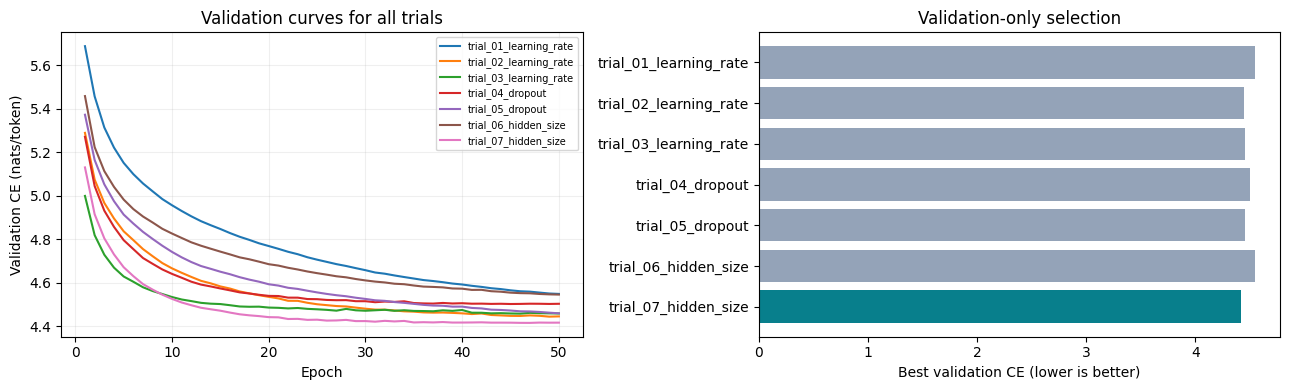

Selected: /content/drive/MyDrive/DSA4213_Assignment1/runs/I_lstm_tuned_s42_v2/trials/trial_07_hidden_size | best epoch: 47 | stop: max_epochs
Total search compute hours: 2.527


In [8]:
STUDY_DIR, STUDY_ID, BASE_CFG = RUN_DIR, RUN_ID, copy.deepcopy(CFG)
assert not ALLOW_PARTIAL_EVALUATION, 'Finish the study before final selection.'
TRIALS_DIR = STUDY_DIR/'trials'; TRIALS_DIR.mkdir(exist_ok=True)

def fit_trial(cfg, trial_dir):
    """No test access: fit on train; select and stop using validation CE."""
    global shuffle_generator
    trial_dir.mkdir(parents=True, exist_ok=True)
    config_path = trial_dir/'config.json'
    if config_path.exists():
        assert read_json(config_path) == cfg, 'Trial configuration mismatch; use a fresh study ID.'
    else:
        if not TRAIN: raise FileNotFoundError('Study incomplete: rerun with TRAIN=True.')
        atomic_json(config_path, cfg)
    for name in ['vocab.json','preprocessing.py','generation_prompts.json','source.json',
                 'data_summary.csv','common_data_config.json','input_fingerprints.json',
                 'lstm_model.py','environment.json','requirements-lock.txt']:
        if not (trial_dir/name).exists(): shutil.copy2(STUDY_DIR/name, trial_dir/name)
    source_hash = sha256(trial_dir/'lstm_model.py')
    seed_all(cfg['seed'])
    shuffle_generator = torch.Generator().manual_seed(cfg['shuffle_seed'])
    loader = DataLoader(datasets['train'], batch_size=cfg['batch_size'], shuffle=True,
                        generator=shuffle_generator, num_workers=0, drop_last=False,
                        pin_memory=DEVICE.type=='cuda')
    net = LSTMLanguageModel(cfg).to(DEVICE)
    opt = torch.optim.Adam(net.parameters(), lr=cfg['learning_rate'], weight_decay=cfg['weight_decay'])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode='min',
        factor=cfg['scheduler_factor'], patience=cfg['scheduler_patience'],
        threshold=cfg['early_stopping_min_delta'], threshold_mode='abs',
        min_lr=cfg['min_learning_rate'])
    hist=[]; best=float('inf'); best_epoch=0; best_state=None; steps=0
    patience_best=float('inf'); bad_epochs=0; done=False; reason=None
    last = trial_dir/'last.pt'
    if last.exists():
        ck=torch.load(last,map_location='cpu',weights_only=True)
        assert ck['config']==cfg and ck['model_source_sha256']==source_hash
        net.load_state_dict(ck['model_state']); opt.load_state_dict(ck['optimizer_state'])
        sched.load_state_dict(ck['scheduler_state'])
        hist=ck['history']; best=ck['best_ce']; best_epoch=ck['best_epoch']
        best_state=ck['best_model_state']; steps=ck['global_step']
        patience_best=ck['patience_best']; bad_epochs=ck['bad_epochs']
        done=ck['complete']; reason=ck['stop_reason']; restore_rng(ck['rng_state'])
    elif TRAIN:
        atomic_torch(trial_dir/'initial_weights.pt',cpu_state(net))
        seed_all(cfg['seed']); shuffle_generator.manual_seed(cfg['shuffle_seed'])
    if not TRAIN and not done:
        raise RuntimeError(f'{cfg["run_id"]} is incomplete. Set TRAIN=True to finish the study.')
    trial_session=trial_dir/'sessions'/SESSION_ID; trial_session.mkdir(parents=True,exist_ok=True)
    atomic_json(trial_session/'environment.json',ENV)
    session_start=time.perf_counter(); start_epoch=len(hist)
    session_train=0.; session_val=0.; session_io=0.
    if not done:
        for epoch in range(len(hist)+1,cfg['epochs']+1):
            net.train(); synchronize(DEVICE); start=time.perf_counter()
            nll=0.; tokens=0; norms=[]; epoch_lr=opt.param_groups[0]['lr']
            if DEVICE.type=='cuda': torch.cuda.reset_peak_memory_stats(DEVICE)
            for x,y in tqdm(loader,desc=f'{cfg["run_id"]} | epoch {epoch}/{cfg["epochs"]}'):
                x,y=x.to(DEVICE),y.to(DEVICE); opt.zero_grad(set_to_none=True)
                loss,count=valid_loss(net(x),y); objective=loss/count
                if not torch.isfinite(objective): raise FloatingPointError('Nonfinite training loss.')
                objective.backward()
                norm=nn.utils.clip_grad_norm_(net.parameters(),cfg['clip_norm'],error_if_nonfinite=True)
                opt.step(); nll+=loss.item(); tokens+=int(count.item()); norms.append(float(norm)); steps+=1
            synchronize(DEVICE); train_s=time.perf_counter()-start
            val=evaluate_model(net,val_loader,DEVICE)
            session_train+=train_s; session_val+=val['seconds']
            improved=val['ce']<best
            if improved: best,best_epoch,best_state=val['ce'],epoch,cpu_state(net)
            if val['ce']<patience_best-cfg['early_stopping_min_delta']:
                patience_best=val['ce']; bad_epochs=0
            else: bad_epochs+=1
            sched.step(val['ce'])
            if bad_epochs>=cfg['early_stopping_patience']: done=True; reason='early_stopping'
            elif epoch==cfg['epochs']: done=True; reason='max_epochs'
            row=dict(epoch=epoch,train_nll_sum=nll,train_tokens=tokens,train_ce=nll/tokens,
                train_ppl=safe_ppl(nll/tokens),val_nll_sum=val['nll_sum'],val_tokens=val['tokens'],
                val_ce=val['ce'],val_ppl=val['ppl'],train_seconds=train_s,
                validation_seconds=val['seconds'],epoch_compute_seconds=train_s+val['seconds'],
                learning_rate=epoch_lr,next_learning_rate=opt.param_groups[0]['lr'],bad_epochs=bad_epochs,
                gradient_norm_mean=float(np.mean(norms)),gradient_norm_max=float(np.max(norms)),
                gradient_clipped_fraction=float(np.mean(np.array(norms)>cfg['clip_norm'])),
                improved_best=improved,global_step=steps,session_id=SESSION_ID,
                training_device=str(DEVICE),gpu_name=ENV['gpu_name'],cpu=ENV['cpu'],
                peak_cuda_allocated_mib=torch.cuda.max_memory_allocated(DEVICE)/2**20 if DEVICE.type=='cuda' else None)
            hist.append(row)
            ck=dict(format_version=2,config=cfg,model_source_sha256=source_hash,
                model_state=cpu_state(net),optimizer_state=opt.state_dict(),scheduler_state=sched.state_dict(),
                history=hist,global_step=steps,best_ce=best,best_epoch=best_epoch,best_model_state=best_state,
                patience_best=patience_best,bad_epochs=bad_epochs,complete=done,stop_reason=reason,rng_state=rng_state())
            io_start=time.perf_counter(); atomic_torch(last,ck)
            pd.DataFrame(hist).to_csv(trial_dir/'history.csv',index=False)
            io_s=time.perf_counter()-io_start; session_io+=io_s
            atomic_json(trial_session/f'epoch_{epoch:02d}_timing.json',dict(epoch=epoch,checkpoint_io_seconds=io_s))
            print(f'val CE={val["ce"]:.4f} | best epoch={best_epoch} | patience={bad_epochs}/{cfg["early_stopping_patience"]} | next LR={opt.param_groups[0]["lr"]:.6g}')
            if done: break
    assert done and best_state is not None
    if not (trial_dir/'best.pt').exists():
        package=dict(config=cfg,model_state=best_state,best_epoch=best_epoch,best_val_ce=best,
            model_source_sha256=source_hash,vocab_sha256=cfg['vocab_sha256'],
            data_manifest_sha256=cfg['data_manifest_sha256'],tokenizer_sha256=sha256(trial_dir/'preprocessing.py'))
        atomic_torch(trial_dir/'best.pt',package); atomic_torch(trial_dir/'weights.pt',best_state)
    if not (trial_dir/'weights.pt').exists(): atomic_torch(trial_dir/'weights.pt',best_state)
    atomic_json(trial_session/'session_timing.json',dict(starting_epoch=start_epoch,ending_epoch=len(hist),
        train_seconds=session_train,validation_seconds=session_val,checkpoint_io_seconds=session_io,
        observed_wall_seconds=time.perf_counter()-session_start))
    summary=dict(trial_id=cfg['run_id'],learning_rate=cfg['learning_rate'],dropout=cfg['dropout'],
        hidden_size=cfg['hidden_size'],best_validation_ce=best,best_epoch=best_epoch,
        epochs_completed=len(hist),stop_reason=reason,complete=done,
        train_seconds=sum(r['train_seconds'] for r in hist),
        validation_seconds=sum(r['validation_seconds'] for r in hist),
        train_including_validation_seconds=sum(r['epoch_compute_seconds'] for r in hist),
        total_parameters=sum(p.numel() for p in net.parameters()),
        checkpoint_io_seconds=sum(read_json(p)['checkpoint_io_seconds'] for p in (trial_dir/'sessions').glob('*/epoch_*_timing.json')),
        config=cfg,relative_dir=str(trial_dir.relative_to(STUDY_DIR)))
    atomic_json(trial_dir/'training_summary.json',summary)
    del net,opt,sched,ck,best_state
    if DEVICE.type=='cuda': torch.cuda.empty_cache()
    return summary

trial_results=[]
def candidate(changes,stage):
    cfg=dict(BASE_CFG,**changes)
    key={k:cfg[k] for k in ['learning_rate','dropout','hidden_size']}
    for r in trial_results:
        if all(r[k]==v for k,v in key.items()): return r
    trial_id=f'trial_{len(trial_results)+1:02d}_{stage}'
    cfg['run_id']=trial_id
    result=fit_trial(cfg,TRIALS_DIR/trial_id)
    result['stage']=stage; trial_results.append(result)
    pd.DataFrame([{k:v for k,v in r.items() if k!='config'} for r in trial_results]).to_csv(STUDY_DIR/'tuning_trials.csv',index=False)
    return result

def winner(results): return min(results,key=lambda r:r['best_validation_ce'])
# Complete every stage before looking at the next stage's hyperparameters.
stage1=[candidate({'learning_rate':lr},'learning_rate') for lr in BASE_CFG['search_learning_rates']]
first=winner(stage1)
stage2=[first]+[candidate({'learning_rate':first['learning_rate'],'dropout':d},'dropout')
                      for d in BASE_CFG['search_dropouts']]
second=winner(stage2)
stage3=[second]+[candidate({'learning_rate':second['learning_rate'],'dropout':second['dropout'],
                          'hidden_size':h},'hidden_size') for h in BASE_CFG['search_hidden_sizes']]
selected_result=winner(trial_results)
assert len(trial_results)==7 and all(r['complete'] for r in trial_results)
selection=dict(study_id=STUDY_ID,selected_trial=selected_result['trial_id'],
    relative_dir=selected_result['relative_dir'],criterion='minimum full-validation token-weighted CE',
    selected_config=selected_result['config'],best_validation_ce=selected_result['best_validation_ce'])
atomic_json(STUDY_DIR/'selection.json',selection)
tuning_summary=dict(study_id=STUDY_ID,trials_completed=len(trial_results),max_epochs_per_trial=BASE_CFG['epochs'],
    total_epochs=sum(r['epochs_completed'] for r in trial_results),
    total_search_compute_seconds=sum(r['train_including_validation_seconds'] for r in trial_results),
    total_checkpoint_io_seconds=sum(r['checkpoint_io_seconds'] for r in trial_results),
    selected_trial_compute_seconds=selected_result['train_including_validation_seconds'],
    selection=selection,note='Search compute includes training and validation of all candidates once, including the winner. Excludes setup, diagnostics, I/O and unsaved interrupted work. Single seed; greedy search; test unused.')
atomic_json(STUDY_DIR/'tuning_summary.json',tuning_summary)
display(pd.DataFrame([{k:v for k,v in r.items() if k not in ['config','relative_dir']} for r in trial_results]))

fig,axes=plt.subplots(1,2,figsize=(13,4))
for r in trial_results:
    h=pd.read_csv(STUDY_DIR/r['relative_dir']/'history.csv')
    axes[0].plot(h.epoch,h.val_ce,label=r['trial_id'])
axes[0].set(xlabel='Epoch',ylabel='Validation CE (nats/token)',title='Validation curves for all trials')
axes[0].legend(fontsize=7); axes[0].grid(alpha=.2)
axes[1].barh([r['trial_id'] for r in trial_results],[r['best_validation_ce'] for r in trial_results],
             color=['#087f8c' if r is selected_result else '#94a3b8' for r in trial_results])
axes[1].set(xlabel='Best validation CE (lower is better)',title='Validation-only selection'); axes[1].invert_yaxis()
fig.tight_layout(); fig.savefig(STUDY_DIR/'tuning_curves.png',bbox_inches='tight'); plt.show()

# All subsequent original evidence cells use only the selected trial.
RUN_DIR=STUDY_DIR/selected_result['relative_dir']; CFG=selected_result['config']; RUN_ID=CFG['run_id']
SESSION_DIR=RUN_DIR/'sessions'/SESSION_ID
model_path=RUN_DIR/'lstm_model.py'
ck=torch.load(RUN_DIR/'last.pt',map_location='cpu',weights_only=True)
history=ck['history']; global_step=ck['global_step']; best_ce=ck['best_ce']; best_epoch=ck['best_epoch']
model=LSTMLanguageModel(CFG).to(DEVICE).eval(); model.load_state_dict(ck['best_model_state'])
del ck
print('Selected:',RUN_DIR,'| best epoch:',best_epoch,'| stop:',selected_result['stop_reason'])
print('Total search compute hours:',round(tuning_summary['total_search_compute_seconds']/3600,3))


## 8. Learnign curves and stability

,epoch,train_ce,val_ce,val_ppl,train_seconds,validation_seconds,gradient_norm_mean,gradient_clipped_fraction,improved_best
0,1,5.6677,5.1312,169.2208,33.5331,1.2901,0.2811,0.0076,True
1,2,5.1529,4.9158,136.4217,33.5128,1.3012,0.2602,0.0000,True
2,3,4.9556,4.8050,122.1231,33.7855,1.2932,0.2628,0.0000,True
3,4,4.8223,4.7312,113.4336,33.7064,1.2940,0.2653,0.0000,True
4,5,4.7220,4.6723,106.9445,33.6731,1.3005,0.2658,0.0000,True
5,6,4.6399,4.6313,102.6506,33.6911,1.3054,0.2666,0.0000,True
6,7,4.5729,4.5947,98.9560,33.7699,1.3045,0.2664,0.0000,True
7,8,4.5174,4.5693,96.4719,33.9378,1.3110,0.2673,0.0000,True
8,9,4.4679,4.5460,94.2556,33.7069,1.2977,0.2677,0.0000,True
9,10,4.4253,4.5267,92.4511,33.7303,1.3019,0.2702,0.0000,True


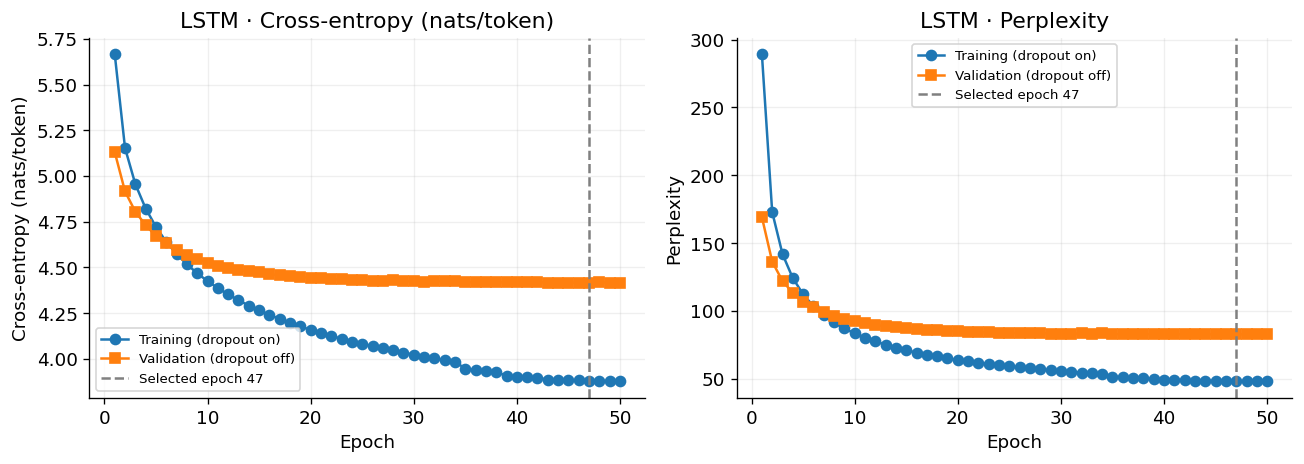

In [9]:
history_df = pd.DataFrame(history)
display(history_df[['epoch','train_ce','val_ce','val_ppl','train_seconds','validation_seconds',
                    'gradient_norm_mean','gradient_clipped_fraction','improved_best']].round(4))
plt.rcParams.update({'font.size':11,'figure.dpi':120,'axes.spines.top':False,'axes.spines.right':False})
fig, axes = plt.subplots(1,2,figsize=(11,4))
for ax,train_col,val_col,label in [(axes[0],'train_ce','val_ce','Cross-entropy (nats/token)'),
                                   (axes[1],'train_ppl','val_ppl','Perplexity')]:
    ax.plot(history_df.epoch,history_df[train_col],marker='o',label='Training (dropout on)')
    ax.plot(history_df.epoch,history_df[val_col],marker='s',label='Validation (dropout off)')
    ax.axvline(best_epoch,color='gray',linestyle='--',label=f'Selected epoch {best_epoch}')
    ax.set(xlabel='Epoch',ylabel=label,title=f'LSTM · {label}'); ax.grid(alpha=0.2); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(RUN_DIR/'learning_curves.png',bbox_inches='tight'); plt.show()

## 9. Evaluate the selected moel and prove disk reload works

In [10]:
loaded = torch.load(RUN_DIR/'best.pt',map_location='cpu',weights_only=True)
assert loaded['config'] == CFG and loaded['model_source_sha256'] == sha256(model_path)
reloaded = LSTMLanguageModel(loaded['config']).to(DEVICE).eval()
reloaded.load_state_dict(loaded['model_state'])
with torch.inference_mode():
    sample_x = torch.from_numpy(arrays['validation'][0][:2]).to(DEVICE)
    torch.testing.assert_close(model(sample_x),reloaded(sample_x),atol=1e-6,rtol=1e-5)
model = reloaded
checkpoint_hash = sha256(RUN_DIR/'best.pt')
metrics = None
if EVALUATE:
    test = evaluate_model(model,test_loader,DEVICE)
    test_info = next(d for d in data_checks if d['split']=='test')
    assert test['tokens'] == test_info['scored_tokens']
    metrics = dict(run_id=RUN_ID,part='I',seed=CFG['seed'],checkpoint='best.pt',checkpoint_sha256=checkpoint_hash,
        data_hash=CFG['data_manifest_sha256'],vocab_hash=CFG['vocab_sha256'],data_version=CFG['data_version'],
        test_target_sha256=test_info['target_sha256'],test_nll_sum=test['nll_sum'],test_token_count=test['tokens'],
        test_ce=test['ce'],test_ppl=test['ppl'],test_unknown_target_rate=test_info['unknown_target_rate'],
        best_epoch=best_epoch,best_validation_ce=best_ce,epochs_completed=len(history),epoch_budget=CFG['epochs'],
        completed_budget=len(history)==CFG['epochs'],training_complete=True,
        stop_reason=selected_result['stop_reason'],study_id=STUDY_ID,
        tuning_trials=len(trial_results),total_search_compute_seconds=tuning_summary['total_search_compute_seconds'],
        total_search_checkpoint_io_seconds=tuning_summary['total_checkpoint_io_seconds'],total_updates=global_step,
        training_token_exposures=int(history_df.train_tokens.sum()),
        total_parameters=sum(p.numel() for p in model.parameters()),
        trainable_parameters=sum(p.numel() for p in model.parameters() if p.requires_grad),
        weights_bytes=(RUN_DIR/'weights.pt').stat().st_size,weights_mib=(RUN_DIR/'weights.pt').stat().st_size/2**20,
        inference_package_mib=(RUN_DIR/'best.pt').stat().st_size/2**20,
        train_seconds=float(history_df.train_seconds.sum()),validation_seconds=float(history_df.validation_seconds.sum()),
        train_including_validation_seconds=float(history_df.epoch_compute_seconds.sum()),
        test_scoring_seconds=test['seconds'],evaluation_device=str(DEVICE),evaluation_gpu=ENV['gpu_name'],
        training_devices='; '.join(sorted(set(history_df.training_device))),
        training_gpu_names='; '.join(sorted({str(v) for v in history_df.gpu_name.dropna()})),
        batch_size=CFG['batch_size'],block_length=T,precision=CFG['precision'])
    atomic_json(SESSION_DIR/'metrics.json',metrics)
    atomic_json(RUN_DIR/'metrics.json',metrics)
    pd.DataFrame([metrics]).to_csv(RUN_DIR/'lm_metrics.csv',index=False)
    display(pd.DataFrame([metrics])[['test_ce','test_ppl','best_epoch','epochs_completed',
        'total_parameters','weights_mib','train_including_validation_seconds']].round(4))
    print('Scored test tokens:',test['tokens'],'| Data version:',common['data_version'])
else: print('Test evaluation skipped by EVALUATE=False.')

,test_ce,test_ppl,best_epoch,epochs_completed,total_parameters,weights_mib,train_including_validation_seconds
0,4.3535,77.7484,47,50,3936592,15.0298,1751.185


Scored test tokens: 252697 | Data version: beacb3de63dc4261


## 10. Matched generation and checkpoint handoff

In [11]:
@torch.inference_mode()
def generate_ids(net, prompt_ids, device, *, max_new_tokens=50, sampling=False,
                 temperature=0.8, top_k=50, seed=123, stop_at_eos=True):
    net.eval()
    context = torch.tensor([[BOS]+list(prompt_ids)],dtype=torch.long,device=device)
    generated = []
    generator = torch.Generator(device=device).manual_seed(seed)
    for _ in range(max_new_tokens):
        logits = net(context[:,-T:])[:,-1,:].clone()
        logits[:,[PAD,BOS,UNK]] = float('-inf')
        if sampling:
            logits = logits/temperature
            values,indices = torch.topk(logits,k=min(top_k,V-3),dim=-1)
            choice = torch.multinomial(values.softmax(-1),1,generator=generator)
            next_id = indices.gather(-1,choice)
        else: next_id = logits.argmax(-1,keepdim=True)
        generated.append(next_id)
        context = torch.cat([context[:,-T:],next_id],dim=1)
        if stop_at_eos and int(next_id.item()) == EOS: break
    return torch.cat(generated,dim=1).squeeze(0) if generated else torch.empty(0,dtype=torch.long,device=device)

# Fresh-instance reload must also reproduce a greedy continuation.
check_model = LSTMLanguageModel(CFG).to(DEVICE).eval(); check_model.load_state_dict(loaded['model_state'])
assert torch.equal(generate_ids(model,prompts[0]['ids'],DEVICE,max_new_tokens=8),
                   generate_ids(check_model,prompts[0]['ids'],DEVICE,max_new_tokens=8))
del check_model

generations = []
if RUN_GENERATION:
    for prompt_id,p in enumerate(prompts):
        for decoding in ['greedy','sample_top50_temperature0.8']:
            ids = generate_ids(model,p['ids'],DEVICE,sampling=decoding!='greedy',seed=CFG['generation_seed']).cpu().tolist()
            record = dict(run_id=RUN_ID,checkpoint_sha256=checkpoint_hash,prompt_id=prompt_id,prompt=p['text'],
                prompt_token_ids=p['ids'],decoding=decoding,temperature=1.0 if decoding=='greedy' else 0.8,
                top_k=None if decoding=='greedy' else 50,seed=CFG['generation_seed'],max_new_tokens=50,
                token_ids=ids,text=' '.join(id_to_token[i] for i in ids),generated_length=len(ids),
                stop_reason='EOS' if ids and ids[-1]==EOS else 'token_limit',
                eos_count=ids.count(EOS),unk_count=ids.count(UNK),device=str(DEVICE))
            generations.append(record)
            print(f'\n{p["text"]} | {decoding}\n{record["text"]}')
    content = ''.join(json.dumps(r,ensure_ascii=False)+'\n' for r in generations)
    (SESSION_DIR/'generation.jsonl').write_text(content,encoding='utf-8')
    (RUN_DIR/'generation.jsonl').write_text(content,encoding='utf-8')


the history of | greedy
the goat puzzle is a fictional character , and the series ' s protagonist is a fictional character . <EOS>

the history of | sample_top50_temperature0.8
a batsman can be lbw in a series of cricket or three years earlier . <EOS>

the city is | greedy
a grade ii listed building in the city of burnside , and the city ' s largest city was built in the city of burnside . <EOS>

the city is | sample_top50_temperature0.8
the third of the most popular world war i ( or ) the austro @ - @ hungarian navy ( later promoted to the rank of darwin in the new york state ) . <EOS>

during the first | greedy
half of the season , the first team was held in the first round of the season . <EOS>

during the first | sample_top50_temperature0.8
time , the battalion was sent to advance in the united states navy along with the command of the new zealand mounted rifles brigade . the following year , the brigade was disbanded in the 6 th , and to the east of the 12 th battalion on 7 octob

## 11. Common inference workload: CPU and optional GPU

In [12]:
benchmark_rows = []; benchmark_summary = []
workload = dict(prompt_sha256=CFG['prompts_sha256'],prompt_count=len(prompts),new_tokens_per_prompt=50,
    decoding='greedy',suppress_ids=[PAD,BOS,UNK],eos_stopping=False,batch_size=1,
    context_length=T,cache_policy='recompute_prefix_no_state',warmup_repeats=1,timed_repeats=3)
workload_id = object_hash(workload)
atomic_json(RUN_DIR/'benchmark_workload.json',dict(workload,workload_id=workload_id))
if RUN_BENCHMARK:
    benchmark_devices = [torch.device('cpu')]
    if BENCHMARK_GPU and torch.cuda.is_available(): benchmark_devices.append(torch.device('cuda'))
    for bench_device in benchmark_devices:
        bench_model = LSTMLanguageModel(CFG).to(bench_device).eval()
        bench_model.load_state_dict(loaded['model_state'])
        def workload_once():
            for p in prompts:
                output = generate_ids(bench_model,p['ids'],bench_device,stop_at_eos=False,max_new_tokens=50)
                assert output.numel() == 50
        workload_once(); synchronize(bench_device)
        for repeat in range(1,4):
            synchronize(bench_device); start = time.perf_counter()
            workload_once()
            synchronize(bench_device); seconds = time.perf_counter()-start
            benchmark_rows.append(dict(run_id=RUN_ID,checkpoint_sha256=checkpoint_hash,workload_id=workload_id,
                device=str(bench_device),device_name=ENV['cpu'] if bench_device.type=='cpu' else ENV['gpu_name'],
                cpu_threads=torch.get_num_threads(),precision='float32',prompt_count=len(prompts),generated_tokens=len(prompts)*50,
                cache_policy='recompute_prefix_no_state',repeat=repeat,seconds=seconds,
                tokens_per_second=len(prompts)*50/seconds,session_id=SESSION_ID))
        del bench_model
    benchmark_df = pd.DataFrame(benchmark_rows)
    benchmark_df.to_csv(SESSION_DIR/'benchmark.csv',index=False)
    benchmark_df.to_csv(RUN_DIR/'benchmark.csv',index=False)
    for device,group in benchmark_df.groupby('device'):
        benchmark_summary.append(dict(device=device,seconds_median=float(group.seconds.median()),
            seconds_min=float(group.seconds.min()),seconds_max=float(group.seconds.max()),
            tokens_per_second_median=float(group.tokens_per_second.median()),
            tokens_per_second_min=float(group.tokens_per_second.min()),tokens_per_second_max=float(group.tokens_per_second.max())))
    summary_df = pd.DataFrame(benchmark_summary)
    summary_df.to_csv(RUN_DIR/'benchmark_summary.csv',index=False)
    display(summary_df.round(3))
else: print('Inference benchmark skipped. Run it before completing the Part I comparison.')

,device,seconds_median,seconds_min,seconds_max,tokens_per_second_median,tokens_per_second_min,tokens_per_second_max
0,cpu,1.190,1.185,1.194,168.024,167.444,168.804
1,cuda,0.277,0.221,0.299,721.665,668.835,903.558


## 12. Save a handoff README and artifact manifest

In [13]:
readme = f"""# {RUN_ID}: DSA4213 Part I LSTM
Data version: {common['data_version']}
Best epoch: {best_epoch}; completed epochs: {len(history)}/{CFG['epochs']}

## Run in Colab
1. Run 01_data_preparation.ipynb and retain its Drive outputs.
2. Open 03_lstm_colab_tuned.ipynb, select a GPU runtime and set PROJECT_ROOT.
3. First run: TRAIN=True, MODE='auto'; Run all.
4. Later: TRAIN=False; Run all. No training occurs, including the diagnostic.
5. Recovery: TRAIN=True, MODE='auto' resumes from last completed epoch.
   A completed run is loaded automatically; choose a new RUN_ID for a new experiment.
6. Save this notebook into your Drive notebooks folder too.

## Dependencies and data access
PyTorch, NumPy, pandas, Matplotlib, tqdm; exact installed versions in requirements-lock.txt.
Use a device-compatible PyTorch installation; a Colab freeze is an environment record,
not a guarantee that a CUDA build installs unchanged on another platform.
Corpus: Salesforce/wikitext, wikitext-2-raw-v1; access/revision in source.json.
Data preparation: normalization, Unicode regex, train-only vocabulary, deduplicated
original splits, independent shifted blocks. Full settings: common_data_config.json.
No raw dataset is downloaded or reprocessed by this notebook.
Main/init seed {CFG['seed']}; shuffle seed {CFG['shuffle_seed']}; sampling seed {CFG['generation_seed']}.

## Load without training (from this folder)
```python
import torch
from lstm_model import LSTMLanguageModel
pkg = torch.load('best.pt', map_location='cpu', weights_only=True)
model = LSTMLanguageModel(pkg['config'])
model.load_state_dict(pkg['model_state'])
model.eval()
# Use preprocessing.py tokenize() and vocab.json token_to_id for new text.
# Inputs are int64 IDs shaped [batch, length]. Prepend BOS=2 and right-pad with PAD=0.
# For next-token generation use at most {T} most-recent context tokens; reset state each call.
# logits = model(input_ids) with torch.inference_mode().
# For Part III mean features: model.encode_mean(input_ids); exclude BOS/PAD/EOS.
```

## Artifacts
best.pt: inference weights + architecture and provenance.
weights.pt: pure state dictionary used for inference-size measurement.
last.pt: current model, optimizer, history, RNG/shuffle states, best weights.
initial_weights.pt: original untrained embedding and non-embedding weights for Part II.
lstm_model.py: reusable model/encoder source; preprocessing.py and vocab.json: input contract.
history.csv and learning_curves.png: convergence/stability evidence.
lm_metrics.csv, generation.jsonl, benchmark*.csv: results when enabled.
sessions/: hardware, environment, timing and result records from each execution.
artifact_manifest.json: inventory with file hashes (does not hash itself).

## Measurement definitions and limitations
CE = summed NLL / scored targets; PPL = exp(CE); score EOS/UNK, exclude PAD.
Output normalization excludes PAD/BOS. Generation also suppresses UNK.
Training time = train loop + in-loop validation, excluding checkpoint I/O/setup.
Timing summary records measured completed-epoch work; unsaved interrupted work is absent.
Inference uses saved {len(prompts)} prompts, 50 tokens each, greedy, no EOS stop,
one warm-up + three repeats, no hidden-state cache. CPU/GPU rows are separate.
Selection: lowest validation CE; earlier epoch wins ties; no test-based tuning.
Staged validation tuning, not parameter-matched. Single-seed result.
Total search compute seconds: {tuning_summary["total_search_compute_seconds"]}.
Selection record: {STUDY_DIR / "selection.json"}.
Stopping reason: {selected_result["stop_reason"]}. Context resets every block.
Part II reuse requires the exact baseline configuration and data. Train frozen-embedding
variants' non-embedding weights from scratch or from initial_weights.pt, never best.pt.
Part III feature extraction uses frozen encoder states; classifier experiments are separate.

## Attribution
Assignment1_2026(1).pdf and DSA4213_Assignment1_Implementation_Plan.pdf supplied the requirements/design.
01_data_preparation.ipynb supplied the actual saved-data schema, tokenizer and four prompts.
PyTorch LSTM API: https://docs.pytorch.org/docs/stable/generated/torch.nn.LSTM.html
PyTorch checkpoint tutorial: https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html
WikiText: Merity et al. (2016), Pointer Sentinel Mixture Models.
This notebook was prepared with substantial ChatGPT coding assistance. Review the code,
acknowledge assistance, and write your own analysis of the measured results.
"""
(RUN_DIR/'README.md').write_text(readme,encoding='utf-8')
session_timings = [read_json(p) for p in sorted((RUN_DIR/'sessions').glob('*/session_timing.json'))]
epoch_timings = [read_json(p) for p in sorted((RUN_DIR/'sessions').glob('*/epoch_*_timing.json'))]
timing_summary = dict(train_seconds=float(history_df.train_seconds.sum()),
    validation_seconds=float(history_df.validation_seconds.sum()),
    train_including_validation_seconds=float(history_df.epoch_compute_seconds.sum()),
    checkpoint_io_seconds_recorded=sum(t['checkpoint_io_seconds'] for t in epoch_timings),
    observed_completed_session_wall_seconds=sum(t['observed_wall_seconds'] for t in session_timings),
    note='Checkpoint I/O includes serialization and history write; wall includes exports. Unsaved interrupted work is not recoverable.')
atomic_json(RUN_DIR/'timing_summary.json',timing_summary)
manifest_files = {}
for path in sorted(RUN_DIR.rglob('*')):
    if path.is_file() and path.name != 'artifact_manifest.json' and not path.name.endswith('.tmp'):
        manifest_files[str(path.relative_to(RUN_DIR))] = dict(bytes=path.stat().st_size,sha256=sha256(path))
atomic_json(RUN_DIR/'artifact_manifest.json',dict(run_id=RUN_ID,data_version=common['data_version'],
    completed_budget=len(history)==CFG['epochs'],training_complete=True,session_id=SESSION_ID,files=manifest_files))
print('Saved run folder:', RUN_DIR)
print('Training complete:', True, '| Stop reason:', selected_result['stop_reason'])
print('Study folder:', STUDY_DIR)
print('This execution: test=',EVALUATE, '| text=',RUN_GENERATION,'| benchmark=',RUN_BENCHMARK)
print('Next time: set TRAIN=False and run all. Keep the same RUN_ID and configuration.')
(STUDY_DIR/'README.md').write_text(f"""# {STUDY_ID}
Selected model folder: {selected_result['relative_dir']}
Open its README.md for reload and downstream reuse instructions.
Study selection: selection.json
All candidate results: tuning_trials.csv and tuning_curves.png
Search cost: tuning_summary.json
Selected trial compute seconds: {selected_result['train_including_validation_seconds']}
Total search compute seconds (includes the selected trial): {tuning_summary['total_search_compute_seconds']}
The selected folder contains best.pt, weights.pt, history.csv, learning_curves.png,
lm_metrics.csv, generation.jsonl, benchmark files and the artifact manifest.
Use the original study RUN_ID in the notebook when reloading; do not substitute the trial ID.
Use TRAIN=False to skip all fitting. Do not use test results to revise the search.
""",encoding='utf-8')


Saved run folder: /content/drive/MyDrive/DSA4213_Assignment1/runs/I_lstm_tuned_s42_v2/trials/trial_07_hidden_size
Training complete: True | Stop reason: max_epochs
Study folder: /content/drive/MyDrive/DSA4213_Assignment1/runs/I_lstm_tuned_s42_v2
This execution: test= True | text= True | benchmark= True
Next time: set TRAIN=False and run all. Keep the same RUN_ID and configuration.


733